This notebook uses the trajectories (computed from ERA5 wind data) as input, and runs the judge CNN on GOES data along these trajectories, to classify mesoscale structures.

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

In [107]:
from judge_along_trajectories import *

# Try out and test functions of judge_along_trajectories.py

In [108]:
with xr.open_dataset(INPUT_file_trajectories) as ds:
    bt_SEP = ds.load()

In [109]:
bt_SEP

<xarray.Dataset> Size: 7MB
Dimensions:          (time_startpoint: 12920, timestep: 15)
Coordinates:
  * timestep         (timestep) int64 120B -42 -36 -30 -24 -18 ... 24 30 36 42
  * time_startpoint  (time_startpoint) datetime64[ns] 103kB 2024-08-01T19:44:...
    orbit            (time_startpoint) <U6 310kB '01009E' '01009E' ... '08369E'
Data variables:
    lat_traj         (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    lon_traj         (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    plev_traj        (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 2MB NaT ... NaT

In [ ]:
# Apply the interpolation
bt_SEP_hourly = interpolate_trajectories_hourly(bt_SEP)
print(f"Original timesteps: {len(bt_SEP.timestep)} (every 6h)")
print(f"Interpolated timesteps: {len(bt_SEP_hourly.timestep)} (every 2h)")
print(f"Original timestep range: {bt_SEP.timestep.min().values} to {bt_SEP.timestep.max().values}")
print(f"Hourly timestep range: {bt_SEP_hourly.timestep.min().values} to {bt_SEP_hourly.timestep.max().values}")

Original timesteps: 15 (every 6h)
Interpolated timesteps: 43 (every 2h)
Original timestep range: -42 to 42
Hourly timestep range: -42 to 42
Loading existing results from disk...


<Axes: xlabel='lon_traj', ylabel='lat_traj'>

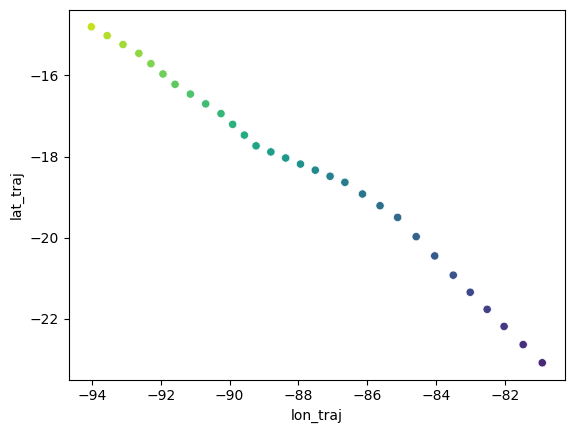

In [ ]:
sns.scatterplot(data=bt_SEP_hourly.isel(time_startpoint=300), x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)

In [ ]:
# set up a dataset to store the results; load existing results if available
results = set_up_results_dataset(bt_SEP_hourly)
results

<xarray.Dataset> Size: 63MB
Dimensions:           (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint   (time_startpoint) datetime64[ns] 103kB 2024-08-01T19:44...
    orbit             (time_startpoint) <U6 310kB '01009E' '01009E' ... '08369E'
  * timestep          (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
Data variables: (12/14)
    lat_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    lon_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    plev_traj         (time_startpoint, timestep) float64 4MB nan nan ... nan
    datetime_traj     (time_startpoint, timestep) datetime64[ns] 4MB NaT ... NaT
    goes_cats         (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_cert         (time_startpoint, timestep) float64 4MB nan nan ... nan
    ...                ...
    goes_ot_gt_1      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_ot_gt_5      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_y_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_x_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lon_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lat_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan

In [116]:
results.sel(time_startpoint=slice('2024-08-01','2024-08-01')).sel(timestep=slice(-8,8))

<xarray.Dataset> Size: 39kB
Dimensions:           (time_startpoint: 37, timestep: 9)
Coordinates:
  * time_startpoint   (time_startpoint) datetime64[ns] 296B 2024-08-01T19:44:...
    orbit             (time_startpoint) <U6 888B '01009E' '01009E' ... '01009E'
  * timestep          (timestep) int64 72B -8 -6 -4 -2 0 2 4 6 8
Data variables: (12/14)
    lat_traj          (time_startpoint, timestep) float64 3kB -4.378 ... -20.68
    lon_traj          (time_startpoint, timestep) float64 3kB -85.52 ... -86.29
    plev_traj         (time_startpoint, timestep) float64 3kB 968.4 ... 948.7
    datetime_traj     (time_startpoint, timestep) datetime64[ns] 3kB 2024-08-...
    goes_cats         (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_cert         (time_startpoint, timestep) float64 3kB nan nan ... nan
    ...                ...
    goes_ot_gt_1      (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_ot_gt_5      (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_y_idx        (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_x_idx        (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_lon_mid      (time_startpoint, timestep) float64 3kB nan nan ... nan
    goes_lat_mid      (time_startpoint, timestep) float64 3kB nan nan ... nan

In [112]:
# Load judge CNN model,fine-tuned for GOES
fine_tuned_model = load_model(judge_for_goes_path)

/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/judge_along_trajectories.py:172: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model

Loaded fine-tuned model from ../judge_for_goes/finetuned_goes_model.pth


In [ ]:
# available GOES times
time_list = ['1400', '1600', '1800', '2000', '2200']

for year in ['2024','2025']:
    if year == '2024':
        month_list = ['09', '10', '11', '12']
    else:
        month_list = ['01', '02', '03', '04', '05', '06', '07', '08','09', '10', '11']
    for month in month_list:
        if month == '02':
            day_list = [f'{i:02d}' for i in range(1, 29)]
        elif month in ['04', '06', '09', '11']:
            day_list = [f'{i:02d}' for i in range(1, 31)]
        else:
            day_list = [f'{i:02d}' for i in range(1, 32)]

        for day in day_list:
            date=year + month + day
            for time in time_list:
                # check if GOES data has already been processed for this date and time
                goes_cats_at_datetime = results.where(results.datetime_traj.dt.strftime('%Y%m%d%H%M') == date + time, drop=True).goes_cats
                if len(goes_cats_at_datetime) == 0:
                    print(f"Datetime does not exist in trajectory data: {date} {time}. Something went wrong.")
                    break
                if ~np.isnan(goes_cats_at_datetime).all():
                    print(f"GOES data already processed for {date} {time}. Skipping.")
                    continue

                results_at_datetime = process_goes_for_trajectory_timestep(date, time, bt_SEP_hourly, fine_tuned_model, plot_results=True)
                if results_at_datetime is not None:
                    results = xr.merge([results, results_at_datetime])
                    print(f"Updated results dataset for {date} {time}\n")
            
                #results.to_netcdf(OUTPUT_file_partial, 
                #        engine='h5netcdf')

                break
            break
        break
    break

# check that orbits are consistent with trajectories

In [98]:
def make_sure_orbit_consistent_along_trajectories(results):
    """
    Ensure that the 'orbit' variable is consistent along the 'timestep' dimension for each trajectory.
    If inconsistent, raise an error. If consistent, reduce 'orbit' to only depend on 'time_startpoint'.
    
    Parameters:
    -----------
    results : xarray.Dataset
        Dataset containing the 'orbit' variable with dimensions ('time_startpoint', 'timestep')
    
    Returns:
    --------
    xarray.Dataset
        Updated dataset with 'orbit' variable reduced to ('time_startpoint') dimension
    """
    if results.orbit.dims == ('time_startpoint', 'timestep'):
        # check if orbit is the same along 'timestep' dimension for each trajectory
        groups = results.orbit.groupby('time_startpoint')
        for date_time, group in groups:
            unique_orbits = np.unique(group.values)
            if (len(unique_orbits)) != 1:
                print('several orbits found for trajectory starting at:')
                print(date_time)
                raise ValueError('Orbit inconsistency found along trajectory timesteps.')
            
        print("Orbit consistency check passed: each trajectory has a single orbit along its timesteps.")
        results['orbit'] = results.orbit.sel(timestep=0)

        return results
    
    elif results.orbit.dims == ('time_startpoint',):
        print("Orbit variable already consistent along trajectories.")
        return results
    
    else:
        raise ValueError("Unexpected dimensions for 'orbit' variable.")

results = make_sure_orbit_consistent_along_trajectories(results)
results

Orbit variable already consistent along trajectories.


<xarray.Dataset> Size: 63MB
Dimensions:           (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint   (time_startpoint) datetime64[ns] 103kB 2024-08-01T19:44...
  * timestep          (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
    orbit             (time_startpoint) <U6 310kB '01009E' '01009E' ... '08369E'
Data variables: (12/14)
    lat_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    lon_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    plev_traj         (time_startpoint, timestep) float64 4MB nan nan ... nan
    datetime_traj     (time_startpoint, timestep) datetime64[ns] 4MB NaT ... NaT
    goes_cats         (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_cert         (time_startpoint, timestep) float64 4MB nan nan ... nan
    ...                ...
    goes_ot_gt_1      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_ot_gt_5      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_y_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_x_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lon_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lat_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan

In [ ]:
results.to_netcdf('/home/jmayer/ACI_research/Code/resources/bt_with_goes.nc', 
                  engine='h5netcdf')